# TP PyTorch, Partie 1 : les bases

## 0. Préparation

In [12]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt

torch.manual_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch version :", torch.__version__)
print("CUDA disponible :", torch.cuda.is_available())
print("Device utilisé  :", device)

PyTorch version : 2.15.0+cpu
CUDA disponible : False
Device utilisé  : cpu


## Workflow général

**Données → Tensors → Modèle → Prédictions → Loss → Backward → Optimizer → Mise à jour**

## 1. Tensors et `device`

In [13]:
# Création : scalaire, vecteur, matrice
scalar = torch.tensor(3.0)
vector = torch.tensor([1.0, 2.0, 3.0])
matrix = torch.tensor([[1.0, 2.0], [3.0, 4.0]])

print("scalar :", scalar, "| shape =", scalar.shape)
print("vector :", vector, "| shape =", vector.shape)
print("matrix :", matrix, "| shape =", matrix.shape, "| dtype =", matrix.dtype)

# Manipulation
x = torch.arange(12)
x2 = x.reshape(3, 4)
print("\nreshape(3, 4) :\n", x2)
print("colonne 1 :", x2[:, 1])
print("ligne 0   :", x2[0, :])

A = torch.tensor([[1., 2.], [3., 4.]])
B = torch.tensor([[2., 0.], [1., 2.]])
print("\nA @ B :\n", A @ B)          # produit matriciel
print("A * B :\n", A * B)            # produit terme à terme
print("mean(A) =", A.mean().item(), "| sum(A) =", A.sum().item())

# Placer un tensor sur le device (CPU ou GPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device utilisé :", device)

x = torch.tensor([1.0, 2.0, 3.0]).to(device)
print("x.device =", x.device)

scalar : tensor(3.) | shape = torch.Size([])
vector : tensor([1., 2., 3.]) | shape = torch.Size([3])
matrix : tensor([[1., 2.],
        [3., 4.]]) | shape = torch.Size([2, 2]) | dtype = torch.float32

reshape(3, 4) :
 tensor([[ 0,  1,  2,  3],
        [ 4,  5,  6,  7],
        [ 8,  9, 10, 11]])
colonne 1 : tensor([1, 5, 9])
ligne 0   : tensor([0, 1, 2, 3])

A @ B :
 tensor([[ 4.,  4.],
        [10.,  8.]])
A * B :
 tensor([[2., 0.],
        [3., 8.]])
mean(A) = 2.5 | sum(A) = 10.0
Device utilisé : cpu
x.device = cpu


## 2. Autograd : calcul des gradients

On prend $y = wx + b$ et $L = (y - 10)^2$, avec $x = 2$, $w = 3$, $b = 1$.
À la main : $\frac{\partial L}{\partial w} = 2(y-10)\,x$ et $\frac{\partial L}{\partial b} = 2(y-10)$.

In [14]:
# Méthode 1 : loss.backward() remplit .grad sur chaque tensor avec requires_grad=True
x = torch.tensor(2.0)
w = torch.tensor(3.0, requires_grad=True)
b = torch.tensor(1.0, requires_grad=True)

y = w * x + b
loss = (y - 10) ** 2
loss.backward()

print("y =", y.item(), "| loss =", loss.item())
print("dL/dw =", w.grad.item())
print("dL/db =", b.grad.item())

y = 7.0 | loss = 9.0
dL/dw = -12.0
dL/db = -6.0


In [15]:
# Méthode 2 : torch.autograd.grad renvoie les gradients sans toucher à .grad
w = torch.tensor(3.0, requires_grad=True)
b = torch.tensor(1.0, requires_grad=True)

y = w * x + b
loss = (y - 10) ** 2
dw, db = torch.autograd.grad(loss, (w, b))

print("dL/dw =", dw.item(), "| dL/db =", db.item())

# Vérification analytique
y_val = 3.0 * 2.0 + 1.0
print("à la main :", 2 * (y_val - 10) * 2.0, 2 * (y_val - 10))

dL/dw = -12.0 | dL/db = -6.0
à la main : -12.0 -6.0


## 3. Un neurone avec `nn.Linear`

Un neurone linéaire calcule $z = \sum_i w_i x_i + b$.

In [16]:
model = nn.Linear(3, 1)
x = torch.tensor([[1.0, 2.0, 3.0]])
y = model(x)

print("Sortie :", y)
print("Poids  :", model.weight)
print("Biais  :", model.bias)

# Vérification à la main : z = w . x + b
print("w . x + b =", (model.weight * x).sum() + model.bias)

Sortie : tensor([[1.5244]], grad_fn=<AddmmBackward0>)
Poids  : Parameter containing:
tensor([[ 0.4414,  0.4792, -0.1353]], requires_grad=True)
Biais  : Parameter containing:
tensor([0.5304], requires_grad=True)
w . x + b = tensor([1.5244], grad_fn=<AddBackward0>)


### Graphe des opérations avec `torchviz`

Ce graphe montre comment `Autograd` a relié la sortie aux paramètres. Il demande l'exécutable Graphviz sur la machine.

In [6]:
from torchviz import make_dot

model = nn.Linear(3, 1)
x = torch.tensor([[1.0, 2.0, 3.0]])
y = model(x)

dot = make_dot(y, params=dict(model.named_parameters()))

try:
    dot.render("graphe_operations", format="png", cleanup=True)   # crée graphe_operations.png
    print("Graphe enregistré dans graphe_operations.png")
except Exception as e:
    print("Rendu impossible (Graphviz absent du PATH ?) :", e)

dot    # affiché directement dans le notebook

epoch  50 | loss = 4.6846
epoch 100 | loss = 0.5542
epoch 150 | loss = 0.3463
epoch 200 | loss = 0.3438
epoch 250 | loss = 0.3438
epoch 300 | loss = 0.3438

w appris = 2.989 (cible 3)
b appris = 2.030 (cible 2)


## 4. Construire un réseau avec `nn.Module`

In [17]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(4, 16),
            nn.ReLU(),
            nn.Linear(16, 8),
            nn.ReLU(),
            nn.Linear(8, 3),
        )

    def forward(self, x):
        return self.net(x)

model = MLP()
print(model)

MLP(
  (net): Sequential(
    (0): Linear(in_features=4, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=8, bias=True)
    (3): ReLU()
    (4): Linear(in_features=8, out_features=3, bias=True)
  )
)


In [18]:
# Même réseau avec nn.Sequential directement
model = nn.Sequential(
    nn.Linear(4, 16),
    nn.ReLU(),
    nn.Linear(16, 8),
    nn.ReLU(),
    nn.Linear(8, 3),
)
print(model)
print("nombre de paramètres :", sum(p.numel() for p in model.parameters()))

Sequential(
  (0): Linear(in_features=4, out_features=16, bias=True)
  (1): ReLU()
  (2): Linear(in_features=16, out_features=8, bias=True)
  (3): ReLU()
  (4): Linear(in_features=8, out_features=3, bias=True)
)
nombre de paramètres : 243


## 5. Fonctions d'activation

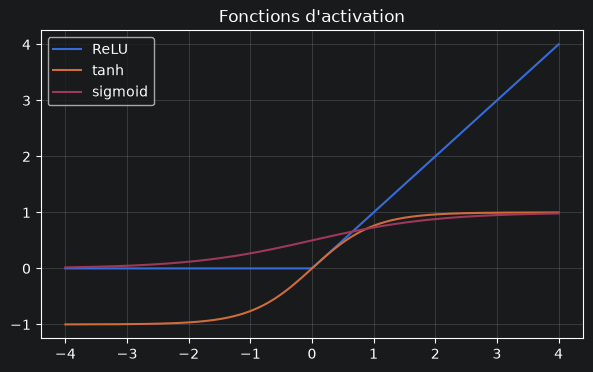

In [19]:
x = torch.linspace(-4, 4, 200)
relu = torch.relu(x)
tanh = torch.tanh(x)
sigmoid = torch.sigmoid(x)

plt.figure(figsize=(7, 4))
plt.plot(x.numpy(), relu.numpy(), label="ReLU")
plt.plot(x.numpy(), tanh.numpy(), label="tanh")
plt.plot(x.numpy(), sigmoid.numpy(), label="sigmoid")
plt.grid(True, alpha=0.3)
plt.legend()
plt.title("Fonctions d'activation")
plt.show()

## 6. Forward propagation

L'appel `model(X)` déclenche automatiquement `model.forward(X)`.

In [20]:
X = torch.randn(5, 4)
predicted = model(X)
print("Shape entrée :", X.shape)
print("Shape sortie :", predicted.shape)

Shape entrée : torch.Size([5, 4])
Shape sortie : torch.Size([5, 3])


## 7. Fonctions de coût

- régression : `nn.MSELoss()`
- classification multi-classe : `nn.CrossEntropyLoss()`
- classification binaire : `nn.BCEWithLogitsLoss()`

In [21]:
# Régression
criterion_reg = nn.MSELoss()
y_pred = torch.tensor([[2.0], [4.0]])
y_true = torch.tensor([[3.0], [5.0]])
print("MSE =", criterion_reg(y_pred, y_true).item())

# Classification multi-classe : logits (N, C) et étiquettes entières (N,)
criterion_cls = nn.CrossEntropyLoss()
pred = torch.tensor([[2.0, 1.0, 0.5], [0.2, 0.1, 2.0]])
y = torch.tensor([0, 2])
print("CrossEntropy =", criterion_cls(pred, y).item())

# Classification binaire : un logit par exemple, étiquettes en float
criterion_bin = nn.BCEWithLogitsLoss()
logits_bin = torch.tensor([[0.8], [-1.2]])
y_bin = torch.tensor([[1.0], [0.0]])
print("BCEWithLogits =", criterion_bin(logits_bin, y_bin).item())

MSE = 1.0
CrossEntropy = 0.36905235052108765
BCEWithLogits = 0.31719154119491577


## 8. Optimizers

L'optimiseur utilise les gradients pour mettre à jour les paramètres.

In [22]:
simple_model = nn.Linear(1, 1)
optimizer = torch.optim.Adam(simple_model.parameters(), lr=1e-2)
print(optimizer)

# Un pas de SGD à la main pour voir l'effet : w <- w - lr * dL/dw
m = nn.Linear(1, 1)
opt_sgd = torch.optim.SGD(m.parameters(), lr=0.1)
x_t, y_t = torch.tensor([[1.0]]), torch.tensor([[5.0]])

print("\nw avant :", m.weight.item())
loss = nn.MSELoss()(m(x_t), y_t)
opt_sgd.zero_grad()
loss.backward()
opt_sgd.step()
print("w après :", m.weight.item())

Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.01
    maximize: False
    weight_decay: 0
)

w avant : 0.21501171588897705
w après : 1.1428110599517822


## 9. La boucle d'apprentissage

C'est le cœur de PyTorch. Ici on apprend $y = 2x + 1$ sur 8 points.

In [23]:
X = torch.randn(8, 1)
y = 2 * X + 1

simple_model = nn.Linear(1, 1)
optimizer = torch.optim.Adam(simple_model.parameters(), lr=1e-2)
criterion = nn.MSELoss()
epochs = 500

for epoch in range(epochs):
    simple_model.train()
    y_pred = simple_model(X)
    loss = criterion(y_pred, y)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    if epoch % 100 == 0:
        print(f"epoch={epoch} loss={loss.item():.4f}")

print("w =", simple_model.weight.item(), "| b =", simple_model.bias.item(), "(cibles : 2 et 1)")

epoch=0 loss=2.0089
epoch=100 loss=0.2241
epoch=200 loss=0.0469
epoch=300 loss=0.0060
epoch=400 loss=0.0005
w = 1.9938710927963257 | b = 1.004249930381775 (cibles : 2 et 1)


## 10. `train()` et `eval()`

`model.train()` et `model.eval()` changent le comportement de `Dropout` et `BatchNorm`.
`eval()` ne désactive pas le calcul des gradients : pour l'inférence on ajoute `torch.inference_mode()`.

In [24]:
class DropoutDemo(nn.Module):
    def __init__(self):
        super().__init__()
        self.dropout = nn.Dropout(p=0.5)

    def forward(self, x):
        return self.dropout(x)

m = DropoutDemo()
x = torch.ones(10)

m.train()
print("train() :", m(x))        # une partie des valeurs est mise à 0, les autres sont multipliées par 2

m.eval()
with torch.inference_mode():
    print("eval()  :", m(x))    # aucune valeur supprimée

train() : tensor([2., 2., 0., 2., 0., 0., 0., 2., 2., 2.])
eval()  : tensor([1., 1., 1., 1., 1., 1., 1., 1., 1., 1.])


## 11. `Dataset` et `DataLoader`

In [25]:
X = torch.randn(100, 3)
y = torch.randn(100, 1)

dataset = TensorDataset(X, y)
loader = DataLoader(dataset, batch_size=16, shuffle=True)

print("taille du dataset :", len(dataset))
print("nombre de batchs  :", len(loader))      # 100 / 16 -> 7 batchs (le dernier a 4 éléments)

for X_batch, y_batch in loader:
    print("Batch X :", X_batch.shape, "| Batch y :", y_batch.shape)
    break

taille du dataset : 100
nombre de batchs  : 7
Batch X : torch.Size([16, 3]) | Batch y : torch.Size([16, 1])


# Partie pratique 1 : régression linéaire

On génère des données proches de $y = 3x + 2 + \text{bruit}$.

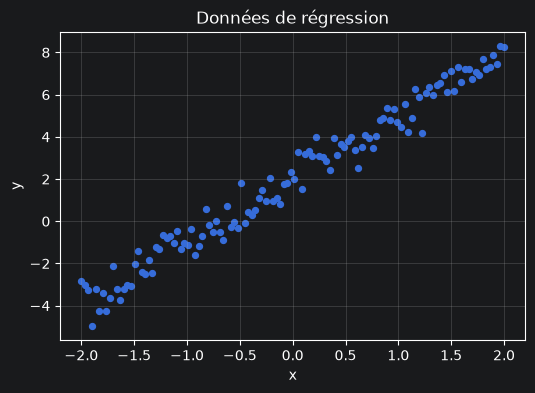

In [26]:
torch.manual_seed(42)

X = torch.linspace(-2, 2, 120).unsqueeze(1)
noise = 0.6 * torch.randn_like(X)
y = 3 * X + 2 + noise

plt.figure(figsize=(6, 4))
plt.scatter(X.numpy(), y.numpy(), s=18)
plt.title("Données de régression")
plt.xlabel("x"); plt.ylabel("y")
plt.grid(True, alpha=0.3)
plt.show()

## 12. Modèle, loss et optimizer

In [27]:
model_reg = nn.Linear(1, 1).to(device)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model_reg.parameters(), lr=0.05)

# Données sur le même device que le modèle
X_d, y_d = X.to(device), y.to(device)

## 13. Entraînement de la régression

In [28]:
losses = []

for epoch in range(300):
    model_reg.train()

    y_pred = model_reg(X_d)              # forward
    loss = criterion(y_pred, y_d)        # loss

    optimizer.zero_grad()                # remise à zéro des gradients
    loss.backward()                      # backward
    optimizer.step()                     # mise à jour des paramètres

    losses.append(loss.item())
    if (epoch + 1) % 50 == 0:
        print(f"epoch {epoch + 1:3d} | loss = {loss.item():.4f}")

print(f"\nw appris = {model_reg.weight.item():.3f} (cible 3)")
print(f"b appris = {model_reg.bias.item():.3f} (cible 2)")

epoch  50 | loss = 4.6846
epoch 100 | loss = 0.5542
epoch 150 | loss = 0.3463
epoch 200 | loss = 0.3438
epoch 250 | loss = 0.3438
epoch 300 | loss = 0.3438

w appris = 2.989 (cible 3)
b appris = 2.030 (cible 2)


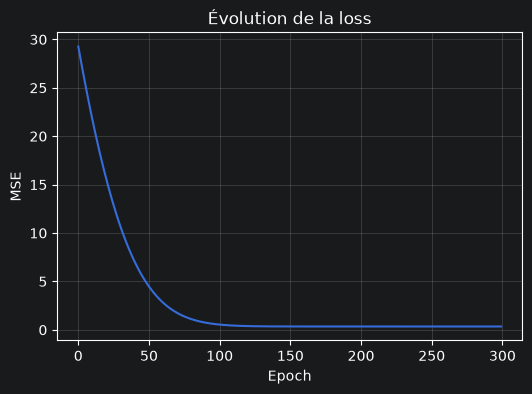

In [29]:
plt.figure(figsize=(6, 4))
plt.plot(losses)
plt.xlabel("Epoch"); plt.ylabel("MSE"); plt.title("Évolution de la loss")
plt.grid(True, alpha=0.3)
plt.show()

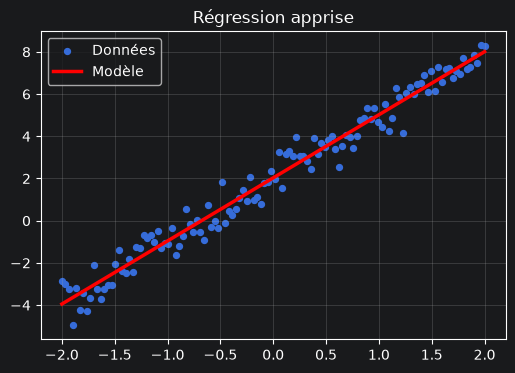

In [30]:
model_reg.eval()
with torch.inference_mode():
    y_hat = model_reg(X_d).cpu()

plt.figure(figsize=(6, 4))
plt.scatter(X.numpy(), y.numpy(), s=18, label="Données")
plt.plot(X.numpy(), y_hat.numpy(), color="red", linewidth=2.5, label="Modèle")
plt.legend(); plt.title("Régression apprise")
plt.grid(True, alpha=0.3)
plt.show()

In [32]:
from torcheval.metrics import R2Score

metric = R2Score()
metric.update(y_hat, y)
r2 = metric.compute()
print(f"R2 Score = {r2:.3f}")

R2 Score = 0.972


# Partie pratique 2 : classification

Deux classes de points en 2D.

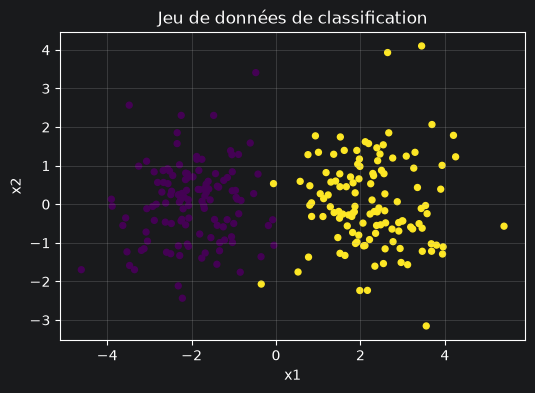

In [33]:
torch.manual_seed(0)

n = 120
class0 = torch.randn(n, 2) + torch.tensor([-2.0, 0.0])
class1 = torch.randn(n, 2) + torch.tensor([ 2.0, 0.0])

X_cls = torch.cat([class0, class1], dim=0)
y_cls = torch.cat([
    torch.zeros(n, dtype=torch.long),
    torch.ones(n, dtype=torch.long),
])

plt.figure(figsize=(6, 4))
plt.scatter(X_cls[:, 0], X_cls[:, 1], c=y_cls, s=18)
plt.title("Jeu de données de classification")
plt.xlabel("x1"); plt.ylabel("x2")
plt.grid(True, alpha=0.3)
plt.show()

## 14. Modèle de classification

Le réseau sort des **logits** (scores bruts), sans Softmax : `CrossEntropyLoss` l'applique en interne.
Les étiquettes sont des entiers (`torch.long`).

In [35]:
class Classifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, 16),
            nn.ReLU(),
            nn.Linear(16, 16),
            nn.ReLU(),
            nn.Linear(16, 2),            # 2 classes -> 2 logits
        )

    def forward(self, x):
        return self.net(x)

model_cls = Classifier().to(device)
criterion_cls = nn.CrossEntropyLoss()
optimizer_cls = torch.optim.Adam(model_cls.parameters(), lr=0.01)

Xc, yc = X_cls.to(device), y_cls.to(device)

## 15. Entraînement de la classification

epoch  50 | loss = 0.0117
epoch 100 | loss = 0.0044
epoch 150 | loss = 0.0019
epoch 200 | loss = 0.0010
epoch 250 | loss = 0.0007


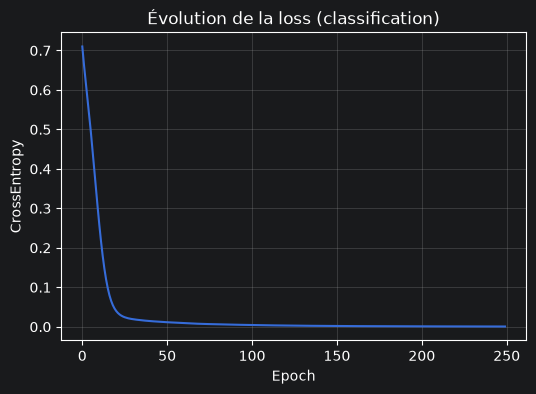

In [36]:
losses_cls = []

for epoch in range(250):
    model_cls.train()

    logits = model_cls(Xc)
    loss = criterion_cls(logits, yc)

    optimizer_cls.zero_grad()
    loss.backward()
    optimizer_cls.step()

    losses_cls.append(loss.item())
    if (epoch + 1) % 50 == 0:
        print(f"epoch {epoch + 1:3d} | loss = {loss.item():.4f}")

plt.figure(figsize=(6, 4))
plt.plot(losses_cls)
plt.xlabel("Epoch"); plt.ylabel("CrossEntropy"); plt.title("Évolution de la loss (classification)")
plt.grid(True, alpha=0.3)
plt.show()

In [37]:
model_cls.eval()
with torch.inference_mode():
    logits = model_cls(Xc)
    pred = logits.argmax(dim=1)          # classe au score maximal
    accuracy = (pred == yc).float().mean()

print(f"Accuracy = {accuracy.item() * 100:.2f}%")

Accuracy = 100.00%


### Métriques de classification avec `torcheval`

Pour toutes les métriques, l'ordre des arguments est `update(prédictions, vraies étiquettes)`.

Accuracy = 1.0000, recall = 1.0000, precision = 1.0000, f1 = 1.0000
tensor([[120.,   0.],
        [  0., 120.]])


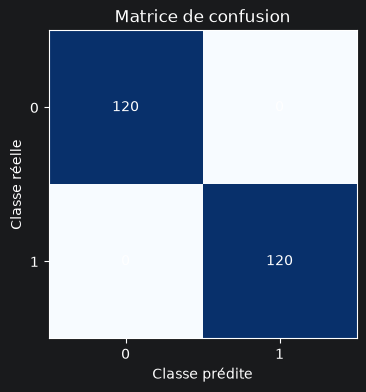

In [38]:
from torcheval.metrics import (BinaryAccuracy, BinaryRecall, BinaryPrecision,
                               BinaryF1Score, BinaryConfusionMatrix)

pred_c, y_c = pred.cpu(), y_cls

accuracy_metric = BinaryAccuracy()
accuracy_metric.update(pred_c, y_c)

recall_metric = BinaryRecall()
recall_metric.update(pred_c, y_c)

precision_metric = BinaryPrecision()
precision_metric.update(pred_c, y_c)

f1_metric = BinaryF1Score()
f1_metric.update(pred_c, y_c)

print(f"Accuracy = {accuracy_metric.compute():.4f}, "
      f"recall = {recall_metric.compute():.4f}, "
      f"precision = {precision_metric.compute():.4f}, "
      f"f1 = {f1_metric.compute():.4f}")

# Matrice de confusion : lignes = classe réelle, colonnes = classe prédite
cm_metric = BinaryConfusionMatrix()
cm_metric.update(pred_c, y_c)
cm = cm_metric.compute()
print(cm)

plt.figure(figsize=(4, 4))
plt.imshow(cm.numpy(), cmap="Blues")
for i in range(2):
    for j in range(2):
        plt.text(j, i, int(cm[i, j]), ha="center", va="center")
plt.xticks([0, 1]); plt.yticks([0, 1])
plt.xlabel("Classe prédite"); plt.ylabel("Classe réelle")
plt.title("Matrice de confusion")
plt.show()

## Visualisation de la frontière de décision

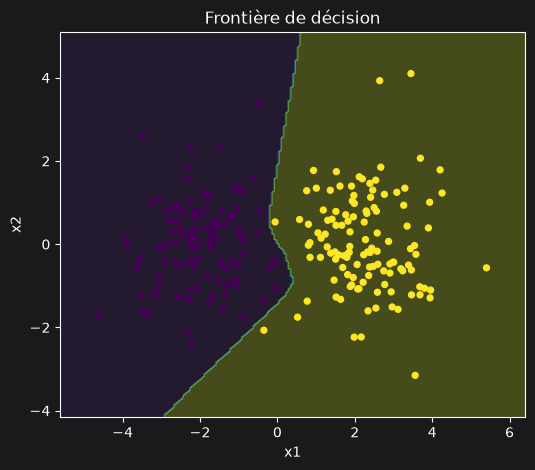

In [39]:
x1_min, x1_max = X_cls[:, 0].min() - 1, X_cls[:, 0].max() + 1
x2_min, x2_max = X_cls[:, 1].min() - 1, X_cls[:, 1].max() + 1

xx1, xx2 = torch.meshgrid(
    torch.linspace(x1_min, x1_max, 200),
    torch.linspace(x2_min, x2_max, 200),
    indexing="ij",
)

grid = torch.stack([xx1.reshape(-1), xx2.reshape(-1)], dim=1).to(device)

model_cls.eval()
with torch.inference_mode():
    zz = model_cls(grid).argmax(dim=1).reshape(xx1.shape).cpu()

plt.figure(figsize=(6, 5))
plt.contourf(xx1.numpy(), xx2.numpy(), zz.numpy(), alpha=0.25)
plt.scatter(X_cls[:, 0], X_cls[:, 1], c=y_cls, s=18)
plt.title("Frontière de décision")
plt.xlabel("x1"); plt.ylabel("x2")
plt.show()

## 16. Sauvegarder et recharger un modèle

In [40]:
path = "classifier_state_dict.pt"
torch.save(model_cls.state_dict(), path)      # on sauvegarde les paramètres, pas la classe
print("Modèle sauvegardé dans", path)

# Pour recharger : recréer la même architecture, puis charger les poids
new_model = Classifier().to(device)
new_model.load_state_dict(torch.load(path, weights_only=True))
new_model.eval()

with torch.inference_mode():
    pred_new = new_model(Xc).argmax(dim=1)

print("Prédictions identiques :", torch.equal(pred, pred_new))

Modèle sauvegardé dans classifier_state_dict.pt
Prédictions identiques : True


# Synthèse

Les briques essentielles de PyTorch sont en place :

1. `Tensor`
2. `nn.Module`
3. `forward()`
4. fonction de coût
5. `optimizer.zero_grad()`
6. `loss.backward()`
7. `optimizer.step()`
8. `train()` / `eval()`
9. `Dataset` / `DataLoader`
10. sauvegarde avec `state_dict()`

Cette mécanique reste la même pour des modèles plus avancés : CNN, Transformers, modèles génératifs ou PINNs.